***NAME = VAROON KUMAR***


***ROLLNO= 24F-AI-044***

***DIABETES***

In [23]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [29]:
df = pd.read_csv("diabetes.csv")

print(df.head())                            # data exploring 
print(df.shape)
print(df.info())
print(df.describe())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148           72.0             35    169.5  33.6   
1            1       85           66.0             29    102.5  26.6   
2            8      183           64.0             32    169.5  23.3   
3            1       89           66.0             23     94.0  28.1   
4            0      137           40.0             35    168.0  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
(768, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose             

In [28]:
print(df.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [30]:
cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

df[cols] = df[cols].replace(0, np.nan)

In [31]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [33]:
for col in cols:
    df[col] = df[col].fillna(df[col].median())                     # missing values handling

In [34]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [35]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']     #outcome will be target 

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42                       #data splitoing in ttrain orr testingge mein
)             

In [38]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)           #normalizations 

In [40]:
svm_model = SVC()

svm_model.fit(X_train, y_train)    #model fittt hogao

SVC()

In [41]:
svm_pred = svm_model.predict(X_test) # PREDiction 

In [42]:
svm_accuracy = accuracy_score(y_test, svm_pred)

print("SVM Accuracy:", svm_accuracy)     # accurNCY 

SVM Accuracy: 0.8246753246753247


In [43]:
tree_model = DecisionTreeClassifier(random_state=42)

tree_model.fit(X_train, y_train)  # deccision treee 

DecisionTreeClassifier(random_state=42)

In [44]:
tree_pred = tree_model.predict(X_test)

In [45]:
tree_accuracy = accuracy_score(y_test, tree_pred)

print("Decision Tree Accuracy:", tree_accuracy)

Decision Tree Accuracy: 0.8441558441558441


In [46]:
print("SVM Accuracy:", svm_accuracy)
print("Decision Tree Accuracy:", tree_accuracy)    #camparing both models 

SVM Accuracy: 0.8246753246753247
Decision Tree Accuracy: 0.8441558441558441


In [47]:
print("SVM Classification Report")
print(classification_report(y_test, svm_pred))   #Classification keliye SVM KA 

SVM Classification Report
              precision    recall  f1-score   support

           0       0.86      0.87      0.86        99
           1       0.76      0.75      0.75        55

    accuracy                           0.82       154
   macro avg       0.81      0.81      0.81       154
weighted avg       0.82      0.82      0.82       154



In [48]:
print("Decision Tree Classification Report")
print(classification_report(y_test, tree_pred))   #classifiction tree keliiye 

Decision Tree Classification Report
              precision    recall  f1-score   support

           0       0.89      0.86      0.88        99
           1       0.76      0.82      0.79        55

    accuracy                           0.84       154
   macro avg       0.83      0.84      0.83       154
weighted avg       0.85      0.84      0.85       154



In [49]:
print("SVM Confusion Matrix")
print(confusion_matrix(y_test, svm_pred))   #confusion matrix  svm 

SVM Confusion Matrix
[[86 13]
 [14 41]]


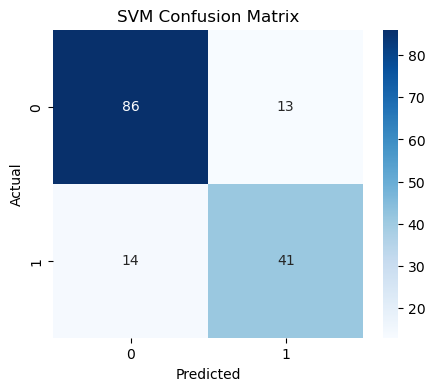

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, svm_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM Confusion Matrix")

plt.show()

In [50]:
print("Decision Tree Confusion Matrix")
print(confusion_matrix(y_test, tree_pred))  # treee ka 

Decision Tree Confusion Matrix
[[85 14]
 [10 45]]


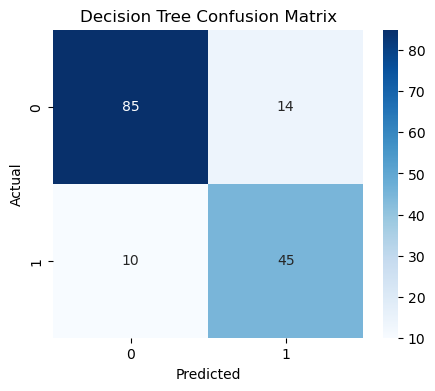

In [52]:
cm = confusion_matrix(y_test, tree_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")

plt.show()

In [53]:
svm_train = svm_model.score(X_train, y_train)
svm_test = svm_model.score(X_test, y_test)

print("SVM Training Accuracy:", svm_train)      # overfitting keliye 
print("SVM Testing Accuracy:", svm_test)

SVM Training Accuracy: 0.8876221498371335
SVM Testing Accuracy: 0.8246753246753247


In [54]:
tree_train = tree_model.score(X_train, y_train)
tree_test = tree_model.score(X_test, y_test)

print("Decision Tree Training Accuracy:", tree_train)
print("Decision Tree Testing Accuracy:", tree_test)

Decision Tree Training Accuracy: 1.0
Decision Tree Testing Accuracy: 0.8441558441558441
